In [3]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import (train_test_split, StratifiedKFold,
 cross_validate, validation_curve,
 GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, roc_auc_score, recall_score,
 precision_score, f1_score, silhouette_score)
from xgboost import XGBClassifier
import joblib

Part 1: Lock the Test Set

In [4]:
path = '/kaggle/input/datasets/au3962/ateeq-ur-rehman/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(path)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0) # blanks have tenure = 0
def build_features(data):
 X = data.drop(columns=['customerID', 'Churn'])
 return pd.get_dummies(X, drop_first=True).astype(float)
y = (df['Churn'] == 'Yes').astype(int)
X = build_features(df)
# The test set is locked away until Part 7. Do not touch it before then.
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(5634, 30) (1409, 30)


## Data Loading and Preprocessing

First, we load the Telco Customer Churn dataset and preprocess the `TotalCharges` column.

```python
path = '/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(path)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)  # blanks have tenure = 0

min 0.780 max 0.828 std 0.0104
Theoretical standard error: 0.0107 -> 95% CI +/- 0.021


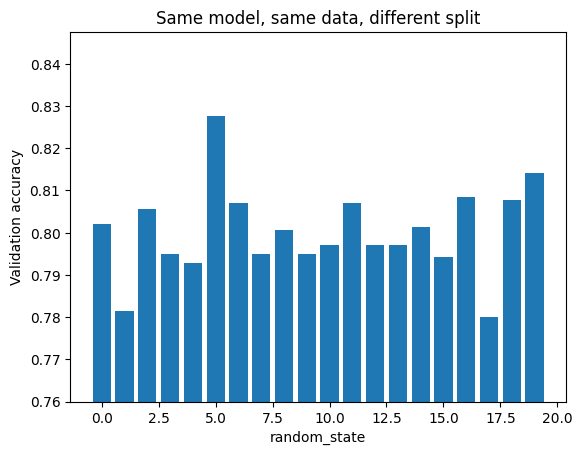

In [5]:
lr = Pipeline([('scale', StandardScaler()),
 ('model', LogisticRegression(max_iter=1000))])
scores = []
for seed in range(20):
 Xa, Xb, ya, yb = train_test_split(X_train, y_train, test_size=0.25,
 random_state=seed, stratify=y_train)
 scores.append(accuracy_score(yb, lr.fit(Xa, ya).predict(Xb)))
scores = np.array(scores)
print(f'min {scores.min():.3f} max {scores.max():.3f} std {scores.std():.4f}')
p, n = scores.mean(), len(yb)
se = np.sqrt(p * (1 - p) / n)
print(f'Theoretical standard error: {se:.4f} -> 95% CI +/- {1.96 * se:.3f}')
plt.bar(range(20), scores)
plt.ylim(scores.min() - 0.02, scores.max() + 0.02)
plt.xlabel('random_state'); plt.ylabel('Validation accuracy')
plt.title('Same model, same data, different split'); plt.show()

## Validation Stability Across Different Random Splits

To evaluate the stability of the Logistic Regression model, the same model is trained and evaluated using 20 different random train-validation splits.

```python
lr = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

scores = []

for seed in range(20):
    Xa, Xb, ya, yb = train_test_split(
        X_train, y_train,
        test_size=0.25,
        random_state=seed,
        stratify=y_train
    )

    scores.append(
        accuracy_score(
            yb,
            lr.fit(Xa, ya).predict(Xb)
        )
    )

scores = np.array(scores)

print(
    f'min {scores.min():.3f} '
    f'max {scores.max():.3f} '
    f'std {scores.std():.4f}'
)

p, n = scores.mean(), len(yb)

se = np.sqrt(p * (1 - p) / n)

print(
    f'Theoretical standard error: {se:.4f} '
    f'-> 95% CI +/- {1.96 * se:.3f}'
)

Part 2: 5-Fold Cross-Validation

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Metrics to evaluate
metrics = ['roc_auc', 'recall', 'f1']

# Function to evaluate a model using cross-validation
def cv_report(name, model):
    r = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=metrics
    )

    row = {'model': name}

    for m in metrics:
        scores = r['test_' + m]
        row[m] = f'{scores.mean():.3f} +/- {scores.std():.3f}'

    return row


# Random Forest model
rf = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42
)

# Compare Logistic Regression and Random Forest
results = pd.DataFrame([
    cv_report('Logistic Regression', lr),
    cv_report('Random Forest', rf)
])

print(results.to_string(index=False))

## 5-Fold Cross-Validation: Logistic Regression vs Random Forest

To compare the stability and performance of Logistic Regression and Random Forest, we use **5-fold stratified cross-validation** on the training data.

Three evaluation metrics are used:

- **ROC-AUC:** Measures how well the model distinguishes churners from non-churners.
- **Recall:** Measures the proportion of actual churners that the model successfully identifies.
- **F1-score:** Provides a balance between precision and recall.

The test set is kept separate and is not used during cross-validation.

### Results

| Model | ROC-AUC | Recall | F1-score |
|---|---:|---:|---:|
| Logistic Regression | 0.846 ± 0.013 | 0.545 ± 0.042 | 0.594 ± 0.030 |
| Random Forest | 0.844 ± 0.011 | 0.496 ± 0.019 | 0.573 ± 0.020 |

### Interpretation

**Logistic Regression** achieves a slightly higher mean ROC-AUC (**0.846**) than Random Forest (**0.844**). This indicates that Logistic Regression has a slightly better ability to rank customers according to their churn risk.

Logistic Regression also has higher mean **recall (0.545)** compared with Random Forest (**0.496**). Therefore, Logistic Regression identifies a larger proportion of actual churners.

The Logistic Regression model also has a higher mean **F1-score (0.594)** compared with Random Forest (**0.573**), indicating a better balance between precision and recall.

The standard deviations show that both models are reasonably stable across the five folds. Random Forest has slightly lower variation for recall and ROC-AUC, but its average performance is lower.

### Conclusion

Based on the 5-fold cross-validation results, **Logistic Regression performs slightly better than Random Forest** on all three selected metrics.

Therefore, Logistic Regression is the preferred model at this stage because it provides:

- Higher ROC-AUC
- Higher recall
- Higher F1-score

However, the final model should be evaluated on the **locked test set only after model selection and tuning are complete**.

Part 3: Hyperparameter Tuning

In [ ]:
Cs = np.logspace(-4, 2, 13)
tr, va = validation_curve(lr, X_train, y_train, param_name='model__C',
 param_range=Cs, cv=cv, scoring='roc_auc')
plt.semilogx(Cs, tr.mean(axis=1), 'o-', label='Train AUC')
plt.semilogx(Cs, va.mean(axis=1), 'o-', label='CV AUC')
plt.xlabel('C (smaller = stronger regularization)'); plt.ylabel('AUC')
plt.legend(); plt.title('Validation curve: Logistic Regression'); plt.show()
print('Best C by CV:', Cs[va.mean(axis=1).argmax()])

## Logistic Regression Validation Curve

The regularization parameter `C` controls the amount of regularization in Logistic Regression.

- A **smaller `C`** means stronger regularization.
- A **larger `C`** means weaker regularization.
- We test 13 different values of `C` using a logarithmic scale.
- The model is evaluated using **ROC-AUC** with 5-fold cross-validation.

```python
Cs = np.logspace(-4, 2, 13)

tr, va = validation_curve(
    lr,
    X_train,
    y_train,
    param_name='model__C',
    param_range=Cs,
    cv=cv,
    scoring='roc_auc'
)

plt.semilogx(
    Cs,
    tr.mean(axis=1),
    'o-',
    label='Train AUC'
)

plt.semilogx(
    Cs,
    va.mean(axis=1),
    'o-',
    label='CV AUC'
)

plt.xlabel('C (smaller = stronger regularization)')
plt.ylabel('AUC')
plt.legend()
plt.title('Validation Curve: Logistic Regression')
plt.show()

print(
    'Best C by CV:',
    Cs[va.mean(axis=1).argmax()]
)

In [ ]:
grid = {'max_depth': [4, 8, 12, None],
 'min_samples_leaf': [1, 5, 20],
 'max_features': ['sqrt', 0.5]}
print('Combinations:', 4 * 3 * 2, ' Fits:', 4 * 3 * 2 * 5)
t0 = time.time()
gs = GridSearchCV(RandomForestClassifier(n_estimators=200, n_jobs=-1,
 random_state=42),
 grid, cv=cv, scoring='roc_auc')
gs.fit(X_train, y_train)
print(f'Grid: best AUC {gs.best_score_:.4f} in {time.time() - t0:.0f}s')
print(gs.best_params_)

## Random Forest Hyperparameter Tuning

After comparing Logistic Regression and Random Forest using cross-validation, we tune the Random Forest hyperparameters to find a better-performing configuration.

We use `GridSearchCV` to test different combinations of:

- `max_depth`: Controls the maximum depth of each decision tree.
- `min_samples_leaf`: Controls the minimum number of samples required in a leaf node.
- `max_features`: Controls the number of features considered when splitting a node.

The model is evaluated using **ROC-AUC** and **5-fold stratified cross-validation**.

There are:

- 4 possible values for `max_depth`
- 3 possible values for `min_samples_leaf`
- 2 possible values for `max_features`

Therefore, the grid contains:

**4 × 3 × 2 = 24 hyperparameter combinations**

Since 5-fold cross-validation is used, this results in:

**24 × 5 = 120 model fits**

### Interpretation

`GridSearchCV` evaluates all 24 hyperparameter combinations using 5-fold cross-validation. The best configuration is selected based on the highest mean cross-validation ROC-AUC.

The output provides:

- **Best AUC:** The highest mean cross-validation ROC-AUC obtained during the grid search.
- **Best parameters:** The Random Forest hyperparameters that produced this score.
- **Runtime:** The approximate time required to complete all 120 model fits.

The test set is not used during hyperparameter tuning. This keeps `X_test` and `y_test` available for the final unbiased evaluation.

### Conclusion

The selected Random Forest configuration is the combination of hyperparameters that achieves the highest cross-validation ROC-AUC among the tested configurations. This tuned model can later be compared with the tuned Logistic Regression model before performing the final evaluation on the locked test set.

In [ ]:
dist = {'max_depth': randint(3, 20),
 'min_samples_leaf': randint(1, 40),
 'max_features': uniform(0.1, 0.8)} # fraction of features
t0 = time.time()
rs = RandomizedSearchCV(RandomForestClassifier(n_estimators=200, n_jobs=-1,
 random_state=42),
 dist, n_iter=24, cv=cv, scoring='roc_auc',
 random_state=42)
rs.fit(X_train, y_train)
print(f'Random: best AUC {rs.best_score_:.4f} in {time.time() - t0:.0f}s')
print(rs.best_params_)
res = pd.DataFrame(rs.cv_results_)
cols = ['param_max_depth', 'param_min_samples_leaf', 'mean_test_score',
 'std_test_score', 'rank_test_score']
print(res[cols].sort_values('rank_test_score').head(5).to_string(index=False))

## Randomized Search Results

Randomized Search was used to tune the Random Forest hyperparameters. Instead of testing every possible combination, the method randomly sampled 24 combinations and evaluated each using 5-fold stratified cross-validation.

The search used ROC-AUC as the evaluation metric.

### Best Result

The best Randomized Search configuration achieved a cross-validation ROC-AUC of **0.8464**.

The selected hyperparameters were:

- **max_depth:** 15
- **min_samples_leaf:** 15
- **max_features:** approximately 0.213

This means that each tree can grow to a maximum depth of 15, each leaf must contain at least 15 samples, and approximately 21.3% of the available features are considered when finding each split.

### Top 5 Configurations

| Rank | max_depth | min_samples_leaf | Mean CV AUC | Std CV AUC |
|---:|---:|---:|---:|---:|
| 1 | 15 | 15 | 0.846440 | 0.011352 |
| 2 | 12 | 16 | 0.846275 | 0.011063 |
| 3 | 8 | 21 | 0.845609 | 0.010548 |
| 4 | 9 | 23 | 0.845245 | 0.012460 |
| 5 | 14 | 27 | 0.845114 | 0.010993 |

The top configurations have very similar ROC-AUC values. The difference between the first and second configurations is very small:

**0.846440 − 0.846275 = 0.000165**

Therefore, the first configuration is only marginally better than the second based on cross-validation ROC-AUC.

### Comparison with the Earlier Random Forest

The earlier Random Forest achieved a mean ROC-AUC of **0.844 ± 0.011** during 5-fold cross-validation.

The best Randomized Search configuration achieved **0.8464**, giving a small improvement in mean ROC-AUC.

This suggests that hyperparameter tuning improved the Random Forest slightly, but the improvement is relatively small.

### Conclusion

Randomized Search found a Random Forest configuration with a cross-validation ROC-AUC of **0.8464**. However, because the improvement over the original Random Forest is small, we should not assume that the tuned model is substantially better.

The final decision should be based on the complete model comparison and, after all model selection is finished, the locked test set should be used once for final evaluation.

Part 4: XGBoost

In [ ]:
X_tr, X_val, y_tr, y_val = train_test_split(
 X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f'scale_pos_weight = {spw:.2f}')
xgb = XGBClassifier(n_estimators=2000, learning_rate=0.03, max_depth=4,
 subsample=0.8, colsample_bytree=0.8,
 eval_metric='logloss', early_stopping_rounds=100,
 random_state=42, n_jobs=-1)
xgb.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_val, y_val)], verbose=False)
print('Best number of trees:', xgb.best_iteration + 1)
val_auc = roc_auc_score(y_val, xgb.predict_proba(X_val)[:, 1])
print(f'Validation AUC: {val_auc:.4f}')

## XGBoost with Early Stopping

XGBoost is evaluated as another classification model for predicting customer churn.

The training data is divided into a training portion and a validation portion. The validation set is used only for monitoring model performance and selecting the appropriate number of boosting trees.

### Handling Class Imbalance

First, we calculate the ratio between non-churned and churned customers:

```python
spw = (y_tr == 0).sum() / (y_tr == 1).sum()

In [ ]:
ev = xgb.evals_result()
plt.plot(ev['validation_0']['logloss'], label='Train log-loss')
plt.plot(ev['validation_1']['logloss'], label='Validation log-loss')
plt.axvline(xgb.best_iteration, color='k', ls='--', label='Early stop')
plt.xlabel('Boosting round'); plt.ylabel('Log-loss')
plt.legend(); plt.title('XGBoost: when to stop adding trees'); plt.show()

In [ ]:
xdist = {'max_depth': randint(2, 7),
 'learning_rate': loguniform(0.01, 0.3),
 'n_estimators': randint(100, 600),
 'subsample': uniform(0.6, 0.4),
 'colsample_bytree': uniform(0.5, 0.5),
 'min_child_weight': randint(1, 10),
 'reg_lambda': loguniform(0.1, 10)}
xs = RandomizedSearchCV(XGBClassifier(eval_metric='logloss', random_state=42,
 n_jobs=-1),
 xdist, n_iter=30, cv=cv, scoring='roc_auc',
 random_state=42)
xs.fit(X_train, y_train)
print(f'XGBoost tuned CV AUC: {xs.best_score_:.4f}')
print({k: round(v, 3) if isinstance(v, float) else v
 for k, v in xs.best_params_.items()})

In [ ]:
imp = pd.Series(xs.best_estimator_.feature_importances_, index=X.columns)
imp.sort_values().tail(10).plot.barh(title='XGBoost feature importance (gain)')
plt.show()

Part 5: K-Means Customer Segmentation

In [ ]:
seg_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
svc = ['PhoneService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
 'TechSupport', 'StreamingTV', 'StreamingMovies']
seg = df[seg_cols].copy()
seg['n_services'] = (df[svc] == 'Yes').sum(axis=1)
Z = StandardScaler().fit_transform(seg) # distances need equal scales
print(seg.describe().round(1))

## Customer Segmentation: Feature Preparation

For customer segmentation, we selected four features that describe customer behavior and spending:

* **Tenure**: Number of months the customer has stayed with the company.
* **MonthlyCharges**: The customer's monthly bill.
* **TotalCharges**: The total amount charged to the customer.
* **n_services**: Number of selected additional services used by the customer.

The `n_services` feature is calculated by counting how many of the selected services have a value of `"Yes"` for each customer. These services include Phone Service, Online Security, Online Backup, Device Protection, Tech Support, Streaming TV, and Streaming Movies.

### Why Standardization Is Needed

The four features have very different numerical ranges. For example, `


In [ ]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
 km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
 inertia.append(km.inertia_)
 sil.append(silhouette_score(Z, km.labels_, sample_size=3000,
 random_state=42))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, 'o-'); ax[0].set_title('Elbow: inertia (WCSS)')
ax[1].plot(ks, sil, 'o-'); ax[1].set_title('Silhouette score')
for a in ax: a.set_xlabel('k')
plt.show()

## Choosing the Number of Clusters

To determine a suitable number of customer segments, we tested different values of **k from 2 to 8** using K-Means clustering.

For each value of `k`, two evaluation measures were calculated:

### 1. Elbow Method — Inertia (WCSS)

**Inertia**, also called **Within-Cluster Sum of Squares (WCSS)**, measures how close the customers are to the center of their assigned cluster.

A lower inertia means that customers within each cluster are more similar to each other.

However, inertia will always decrease as the number of clusters increases. Therefore, we look for an **"elbow" point**, where increasing `k` further produces only a small improvement.

### 2. Silhouette Score

The **silhouette score** measures how well-separated the clusters are.

* A value closer to **1** indicates well-separated and compact clusters.
* A value around **0** indicates overlapping clusters.
* A negative value suggests that some customers may be assigned to the wrong cluster.

Therefore, a **higher silhouette score is better**.

We used `sample_size=3000` when calculating the silhouette score to reduce computation time while still evaluating a representative sample of the 7,043 customers.

### K-Means Configuration

For every value of `k`, K-Means was run with:

* `n_clusters=k`: Number of customer segments.
* `n_init=10`: Runs K-Means 10 times with different initial centroids and keeps the best result.
* `random_state=42`: Makes the results reproducible.

The elbow plot and silhouette plot are used together to select the final number of customer segments. The final `k` should provide a reasonable balance between **low inertia** and a **high silhouette score**, rather than choosing a large number of clusters simply because it reduces inertia.


Part 6: Principal Component Analysis

In [ ]:
Xs = StandardScaler().fit_transform(X_train)
pca = PCA().fit(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)
print('Components for 90% variance:', np.argmax(cum >= 0.90) + 1,
 'of', X_train.shape[1])
plt.bar(range(1, 16), pca.explained_variance_ratio_[:15], label='Per component')
plt.plot(range(1, 16), cum[:15], 'o-', color='C1', label='Cumulative')
plt.xlabel('Principal component'); plt.ylabel('Explained variance ratio')
plt.legend(); plt.title('Scree plot'); plt.show()

## Principal Component Analysis (PCA)

Principal Component Analysis (PCA) was used to understand how much of the information in the 30 original features can be represented using a smaller number of dimensions.

### Step 1: Standardization

The training features were standardized using `StandardScaler` before applying PCA. This is important because the original features can have different scales, and PCA is affected by feature magnitude.

### Step 2: Applying PCA

PCA was first fitted with all **30 components** so that we could calculate the amount of variance explained by each component.

The `explained_variance_ratio_` shows the proportion of the total dataset variance explained by each principal component.

The cumulative explained variance is calculated by adding these proportions progressively.

### Result

The output shows:

**15 components are required to explain at least 90% of the variance, out of the original 30 features.**

This means PCA can reduce the dimensionality from **30 features to 15 components** while retaining approximately **90% of the information/variance** in the training data.

### Scree Plot

The scree plot shows two things:

* **Per-component explained variance**: How much variance each individual principal component explains.
* **Cumulative explained variance**: How much total variance is explained as more components are added.




In [ ]:
P = PCA(n_components=2).fit(Xs)
T = P.transform(Xs)
plt.figure(figsize=(7, 5))
plt.scatter(T[:, 0], T[:, 1], c=y_train, cmap='coolwarm', s=6, alpha=0.5)
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('Customers in 2D, colored by churn (red = churned)'); plt.show()
load = pd.Series(P.components_[0], index=X.columns)
print('PC1 top loadings:')
order = load.abs().sort_values(ascending=False).index
print(load.reindex(order).head(6).round(3))

## PCA 2D Visualization and Feature Loadings

To visualize the customer data in two dimensions, PCA was fitted with **2 principal components (PC1 and PC2)**.

The original standardized dataset contains 30 features, so reducing it to two components allows us to plot the customers on a 2D graph.

### 2D PCA Visualization

Each point in the scatter plot represents one customer.

* **PC1** is the first principal component.
* **PC2** is the second principal component.
* Customers are colored according to their actual churn status.
* Red represents customers who **churned**.
* Blue represents customers who **did not churn**.

The purpose of this visualization is to see whether churned and non-churned customers form clearly separated groups in the two-dimensional PCA space.

If the two colors overlap substantially, it indicates that churn is not completely separable using only the first two principal components.

### PC1 Feature Loadings

The PCA loadings show how strongly each original feature contributes to PC1.

The six largest absolute loadings were:

| Feature                              | PC1 Loading |
| ------------------------------------ | ----------: |
| InternetService_No                   |       0.302 |
| OnlineSecurity_No internet service   |       0.302 |
| TechSupport_No internet service      |       0.302 |
| StreamingTV_No internet service      |       0.302 |
| DeviceProtection_No internet service |       0.302 |
| OnlineBackup_No internet service     |       0.302 |

All six features have the same positive loading of approximately **0.302**.

This suggests that PC1 is strongly associated with a common customer characteristic: **customers who do not have internet service**. The repeated pattern occurs because several service-related variables contain the `"No internet service"` category.

### Important Interpretation

The loading does **not** mean that these features individually cause churn. Instead, PCA is identifying a direction in the feature space where these variables vary together.

Therefore, PC1 can be interpreted as being strongly related to the distinction between customers **with and without internet service**.

The PCA plot is useful for visualization, but the original features are still preferable when we need an interpretable explanation of **why a customer is likely to churn**.


Part 7: Choose by CV, Test Once

In [ ]:
candidates = {
 'LR (tuned C)': lr.set_params(model__C=Cs[va.mean(axis=1).argmax()]),
 'RF (random search)': rs.best_estimator_,
 'XGBoost (tuned)': xs.best_estimator_,
}
rows = []
for name, m in candidates.items():
 cvs = cross_validate(m, X_train, y_train, cv=cv, scoring='roc_auc')
 rows.append({'model': name,
 'cv_auc': cvs['test_score'].mean(),
 'cv_std': cvs['test_score'].std()})
cmp = pd.DataFrame(rows)
print(cmp.round(4).to_string(index=False))

In [ ]:
best_name = cmp.loc[cmp['cv_auc'].idxmax(), 'model'] # chosen by CV only
best = candidates[best_name].fit(X_train, y_train)
prob = best.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
print(f'{best_name} on the test set (used once):')
print(f'AUC {roc_auc_score(y_test, prob):.4f} '
 f'recall {recall_score(y_test, pred):.3f} '
 f'precision {precision_score(y_test, pred):.3f}')
joblib.dump(best, 'churn_model.joblib') # you will deploy this in Week 4

## Final Model Selection and Test Evaluation

After tuning the individual models, we compared Logistic Regression, Random Forest, and XGBoost using **5-fold stratified cross-validation** on the training data.

### Cross-Validation Comparison

| Model                         | Mean CV ROC-AUC | CV Standard Deviation |
| ----------------------------- | --------------: | --------------------: |
| Logistic Regression (tuned C) |          0.8464 |                0.0129 |
| Random Forest (random search) |          0.8464 |                0.0114 |
| XGBoost (tuned)               |      **0.8502** |                0.0117 |

XGBoost achieved the highest mean CV ROC-AUC (**0.8502**), so it was selected as the final model based **only on cross-validation performance**.

The test set was not used during model selection. This helps prevent information from the test set from influencing the choice of model.

### Final Test Evaluation

The selected XGBoost model was then refitted using the complete training set and evaluated on the held-out test set **once**.

The final test results were:

* **ROC-AUC:** 0.8483
* **Recall:** 0.521
* **Precision:** 0.659
* **Classification threshold:** 0.50

The test ROC-AUC of **0.8483** is close to the cross-validation ROC-AUC of **0.8502**, suggesting that the model generalizes reasonably well to unseen customers.

At the default threshold of 0.50, the model correctly identifies approximately **52.1% of the actual churners**, while the precision of **0.659** means that about 65.9% of customers predicted as churners actually churned.

### Final Model

**XGBoost (tuned)** was selected as the final model because it achieved the highest cross-validated ROC-AUC among the three candidates.

The trained model was saved as:

`churn_model.joblib`

This saved model can be loaded later for deployment and prediction without retraining it.


In [ ]:
# Run these cells at the END of your Week 3 notebook, after "Run All",
# so that df, X, build_features and churn_model.joblib already exist.
import json
import joblib
import sklearn
import numpy as np
import pandas as pd
model = joblib.load('/kaggle/working/churn_model.joblib')
cols = list(model.feature_names_in_) # the exact training columns, in order
final = model[-1] if hasattr(model, 'steps') else model
print('Model :', type(final).__name__)
print('Feature columns:', len(cols))
print('scikit-learn :', sklearn.__version__) # you will pin this version

In [ ]:
RAW_COLS = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
 'PhoneService', 'MultipleLines', 'InternetService',
 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges',
 'TotalCharges']
def prepare_input(raw, columns):
 """Turn raw customer rows into exactly the columns the model saw."""
 X = pd.get_dummies(raw[RAW_COLS]) # NO drop_first when serving
 return X.reindex(columns=columns, fill_value=0).astype(float)

In [ ]:
one = df[df['Contract'] == 'Two year'].head(1)
wrong = build_features(one).reindex(columns=cols, fill_value=0) # Week 3 way
right = prepare_input(one, cols)
print('Contract columns, wrong:', wrong.filter(like='Contract').values)
print('Contract columns, right:', right.filter(like='Contract').values)
print(f'P(churn) wrong: {model.predict_proba(wrong)[0, 1]:.3f}')
print(f'P(churn) right: {model.predict_proba(right)[0, 1]:.3f}')

In [ ]:
raw = df.drop(columns=['Churn'])
served = prepare_input(raw, cols)
p_train = model.predict_proba(X[cols])[:, 1] # how the model was evaluated
p_serve = model.predict_proba(served)[:, 1] # how the app will call it
print('Largest difference:', np.abs(p_train - p_serve).max())
assert np.allclose(p_train, p_serve), 'Training-serving skew detected!'
print(f'Parity test passed on {len(raw)} customers')

In [ ]:
def what_if(model, row, columns, changes):
 base = model.predict_proba(prepare_input(row, columns))[0, 1]
 rows = []
 for feature, value in changes:
     alt = row.copy()
     alt[feature] = value
 p = model.predict_proba(prepare_input(alt, columns))[0, 1]
 rows.append({'change': f'{feature} = {value}',
 'p_churn': round(p, 3), 'delta': round(p - base, 3)})
 return base, pd.DataFrame(rows)
row = raw.iloc[[int(np.argmax(p_serve))]] # the riskiest customer
base, table = what_if(model, row, cols, [
 ('Contract', 'One year'), ('Contract', 'Two year'),
 ('PaymentMethod', 'Credit card (automatic)')])
print(f'Baseline P(churn) = {base:.3f}')
print(table.to_string(index=False))

In [ ]:
meta = {
 'model_name': type(final).__name__,
 'sklearn_version': sklearn.__version__,
 'feature_columns': cols,
 'threshold': 0.30, # your choice from the Week 2 cost analysis
 'cv_auc': 0.845, # replace with YOUR Week 3 CV mean
 'cv_auc_std': 0.012, # replace with YOUR Week 3 CV std
 'test_auc': 0.840, # replace with YOUR Week 3 test AUC
 'training_data': 'IBM Telco Customer Churn, 7,043 customers',
 'version': '1.0',
}
with open('/kaggle/working/model_meta.json', 'w') as f:
 json.dump(meta, f, indent=2)
print('Saved model_meta.json with', len(cols), 'columns')
sample = df.drop(columns=['Churn']).sample(50, random_state=1)
sample.to_csv('/kaggle/working/sample_customers.csv', index=False)
print('Saved 50 customers for the batch demo')

In [ ]:

import joblib
import os
import zipfile
from IPython.display import FileLink, display

# Save the trained model
joblib.dump(final, "/kaggle/working/churn_model.joblib")

# Put all three files into one ZIP
files = [
    "churn_model.joblib",
    "model_meta.json",
    "sample_customers.csv"
]

with zipfile.ZipFile("/kaggle/working/churn_files.zip", "w") as z:
    for name in files:
        path = "/kaggle/working/" + name
        if os.path.exists(path):
            z.write(path, arcname=name)
        else:
            print("Missing file:", name)

print("ZIP file created. Click the link below:")
display(FileLink("/kaggle/working/churn_files.zip"))